# 01 - Exploratory Data Analysis
UCI Heart Disease (Cleveland). Run `python -m src.download_data` and
`python -m src.data_processing` first. All figures are also produced headlessly by
`python -m src.eda` and saved to `reports/figures/eda/`.

Write your own observations in the markdown cells below each figure.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")

import pandas as pd
from src import eda
from src.data_processing import PROCESSED_PATH, TARGET

df = pd.read_csv(PROCESSED_PATH)
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## 1. Overview and summary statistics

In [2]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## 2. Missing values
The missing cells are imputed inside the model pipeline, so the same logic applies at serving time.

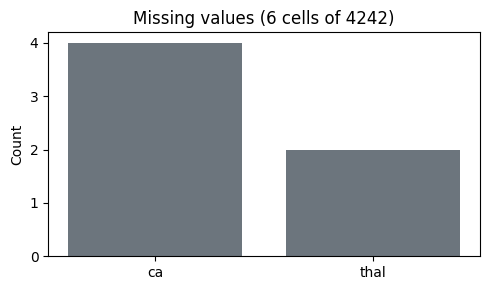

In [3]:
eda.missing_values(df);

Observation:
Only [6] cells are missing, [4] in ca and [2] in thal, which is under 2% of rows. Instead of dropping these rows, I impute them inside the model 
pipeline (most frequent value), so the same rule is applied automatically when the API receives a request with these fields missing.

## 3. Class balance

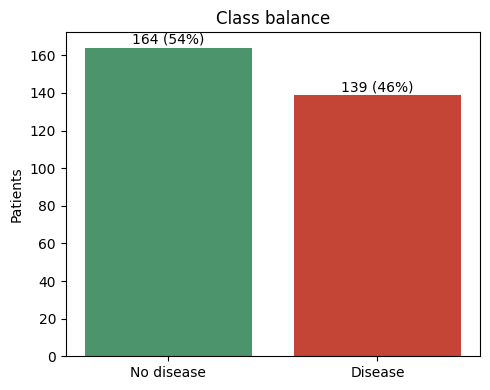

In [4]:
eda.class_balance(df);

**Observation:**
The dataset is close to balanced: [164] patients (≈54%) without disease and [139] (≈46%) with it. Because neither class dominates, accuracy is a meaningful metric here, but I still use stratified splits and cross-validation so every fold keeps the same ratio, and I report precision, recall and ROC-AUC alongside accuracy.

## 4. Numeric features by diagnosis

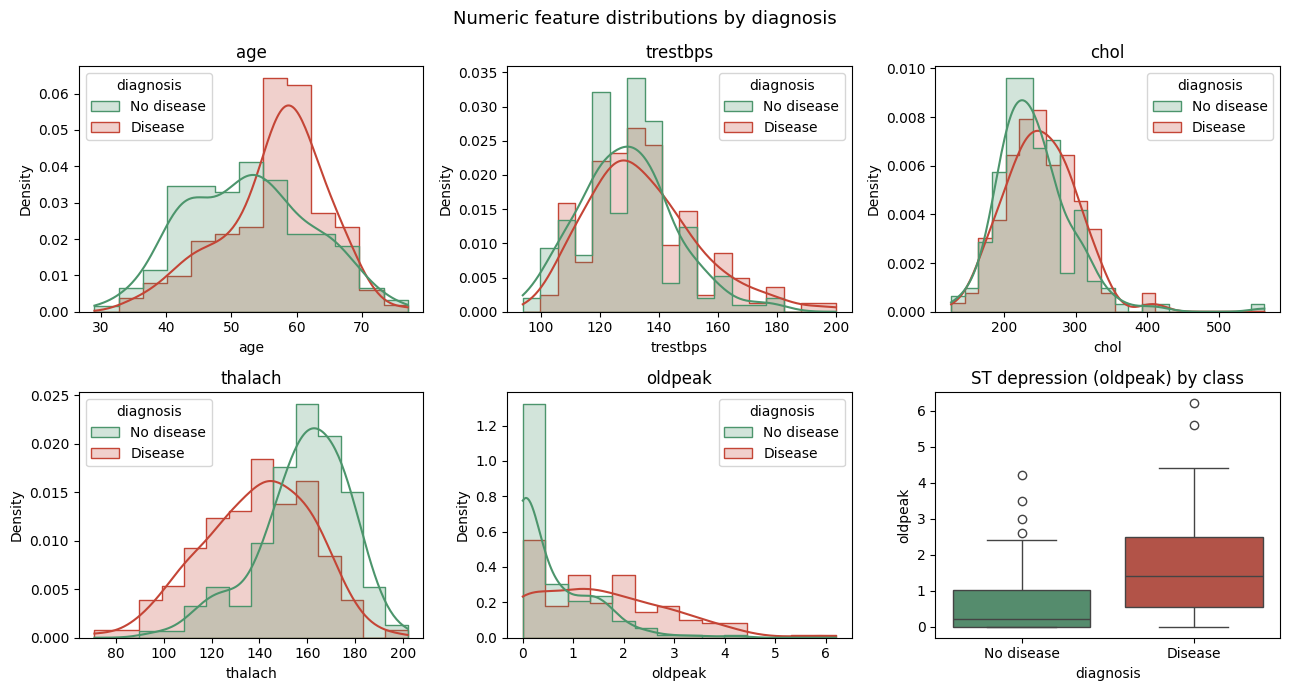

In [5]:
eda.numeric_distributions(df);

**Observation:** 
thalach (max heart rate) and oldpeak (ST depression) separate the classes most clearly. Patients with disease reach a noticeably lower peak heart rate and show higher ST depression during exercise. age shifts slightly higher in the disease group, while chol and trestbps overlap almost completely between classes, so on their own they carry little signal.

## 5. Disease rate per category

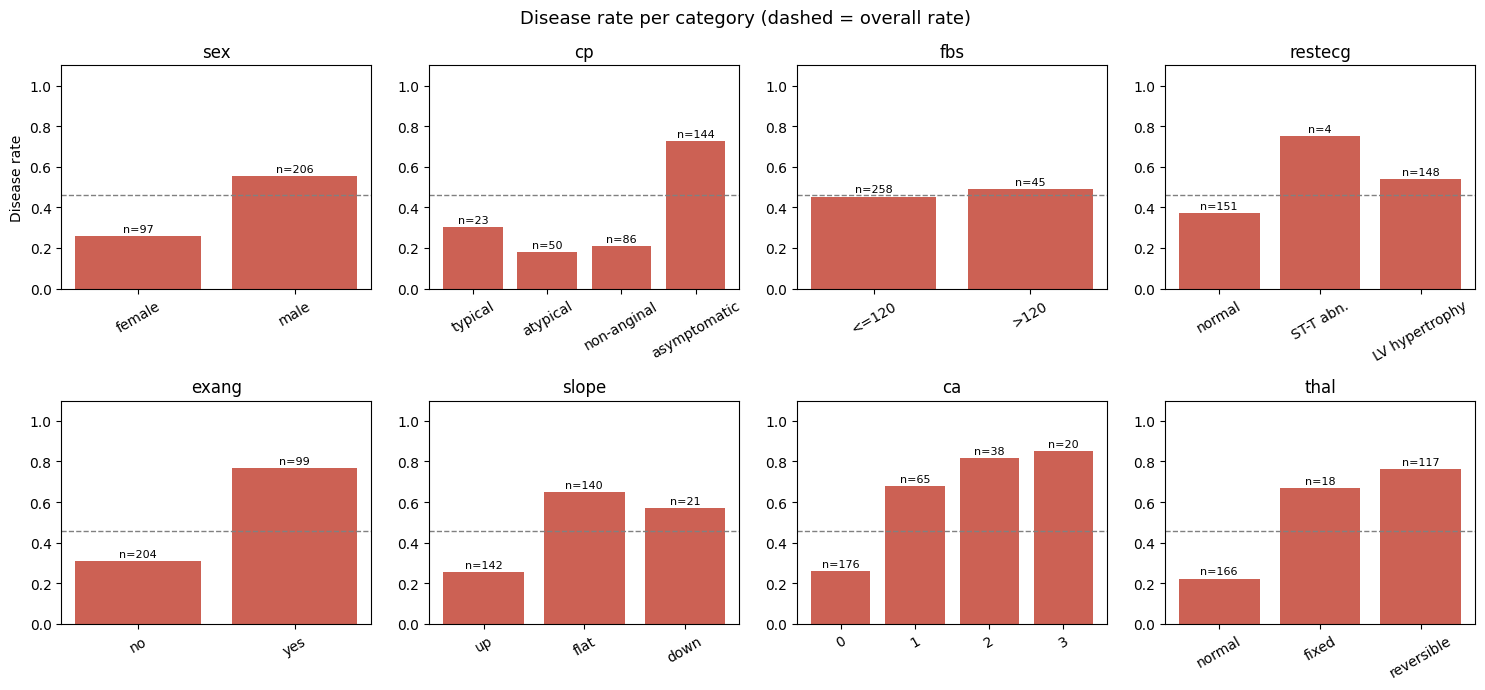

In [6]:
eda.categorical_rates(df); 

**Observation:** 
Several categorical features show strong differences. Asymptomatic chest pain (cp = 4) has a disease rate of about [70%+], far above the overall rate, even though it sounds counter-intuitive. Exercise-induced angina (exang = yes), a reversible thalassemia defect (thal = 7) and having one or more major vessels coloured (ca ≥ 1) are also associated with much higher rates. Males have a higher rate than females. Fasting blood sugar (fbs) makes almost no difference. Since cp, restecg, slope and thal are category codes rather than measurements, I one-hot encode them instead of treating them as numbers.

## 6. Correlations

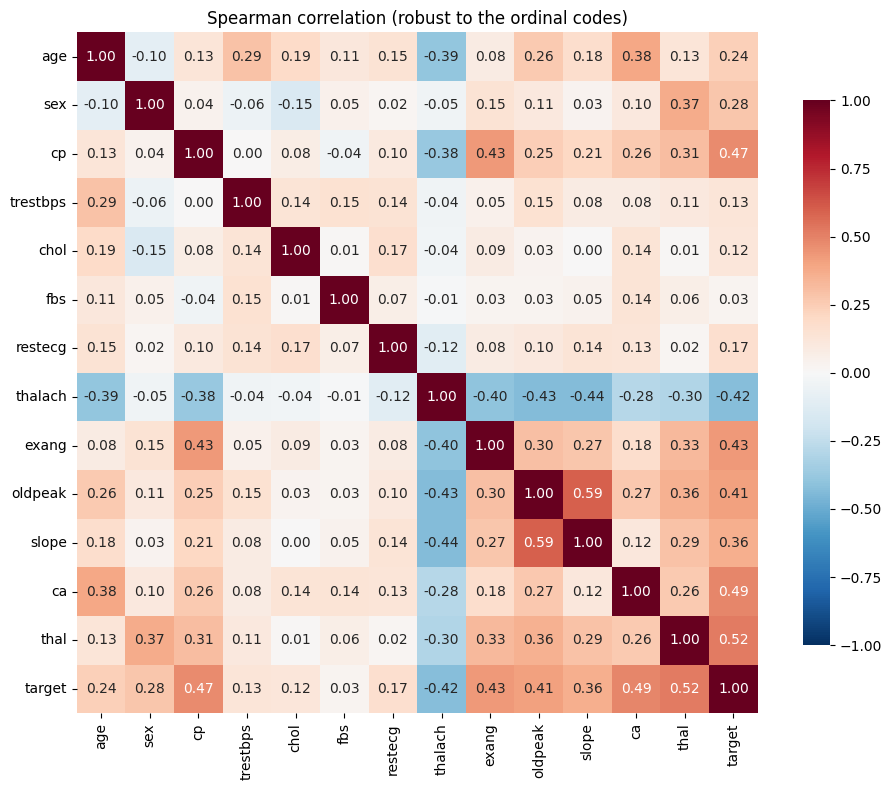

In [7]:
eda.correlation_heatmap(df); 

In [8]:
eda.target_correlations(df).round(3).to_frame('spearman_with_target')

,spearman_with_target
thal,0.522
ca,0.489
cp,0.472
exang,0.432
thalach,-0.423
oldpeak,0.413
slope,0.364
sex,0.277
age,0.237
restecg,0.169


**Observation:** 
Using Spearman correlation (better suited to the ordinal codes), the features most related to the target are [thal, ca, cp, oldpeak, exang] positively and thalach negatively, which matches the plots above. Correlations between features are moderate at most (no pair is close to ±1), so multicollinearity isn't a serious concern and I keep all features.

## 7. Engineered feature: % of age-predicted max heart rate
`pct_max_hr = thalach / (220 - age)` - added in `src/features.py`.

In [9]:
tmp = df.assign(pct_max_hr=df["thalach"] / (220 - df["age"]))
tmp.groupby(TARGET)[["thalach", "pct_max_hr"]].describe().round(3)

thalach                                                     pct_max_hr  \
         count     mean     std   min     25%    50%    75%    max      count   
target                                                                          
0        164.0  158.378  19.199  96.0  148.75  161.0  172.0  202.0      164.0   
1        139.0  139.259  22.593  71.0  125.00  142.0  156.5  195.0      139.0   

                                                         
         mean    std    min    25%    50%    75%    max  
target                                                   
0       0.946  0.099  0.600  0.900  0.961  1.006  1.140  
1       0.854  0.140  0.464  0.754  0.866  0.968  1.175

**Observation:** 
Raw thalach partly reflects age, since older people naturally have a lower maximum heart rate. pct_max_hr adjusts for this by dividing by the age-predicted maximum (220 − age). The disease group has a lower mean [≈0.85 vs ≈0.97], so the feature captures "how hard the patient could exercise for their age". It is computed inside the pipeline, so the API calculates it automatically.

## 8. Save all figures for the report

In [10]:
eda.run_all(df)

[PosixPath('reports/figures/eda/class_balance.png'),
 PosixPath('reports/figures/eda/missing_values.png'),
 PosixPath('reports/figures/eda/numeric_distributions.png'),
 PosixPath('reports/figures/eda/categorical_disease_rates.png'),
 PosixPath('reports/figures/eda/correlation_heatmap.png')]

## Summary
- The data is small (303 patients) and nearly balanced, with very little missing data, handled by in-pipeline imputation.
- Exercise-test features (thalach, oldpeak, exang) and diagnostic features (cp, ca, thal) carry the strongest signal; cholesterol, resting BP and fasting blood sugar are weak on their own.
- Categorical codes are one-hot encoded and continuous features are scaled, all within one saved scikit-learn pipeline.
- I added pct_max_hr to make heart rate comparable across ages.
- Given the small dataset, I compare models with stratified 5-fold cross-validation rather than relying on a single split.